# DBM301 – Assignment 2 – Đề 2
**Nhóm:** Group 3  
**Thành viên:** Thắng, Hưng, Phú, Quốc Anh

Notebook làm trong lượt này chỉ bao gồm **phần Thắng: Phần 1 / WBS 2.0–2.7**. Code chuẩn bị dữ liệu và taxonomy nằm trực tiếp trong notebook; không import `src/` hay đọc mapping đã sinh. Chỉ đọc hai CSV được giảng viên cấp. Cố định seed = 42.

## Thiết lập và hàm dùng chung cho Phần 1
Các hàm dưới đây chỉ đọc/kiểm tra CSV, tách món và tạo ma trận Boolean cần cho EDA. Chạy từ đầu để tái tạo kết quả.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED=42
np.random.seed(SEED)
TARGET='other vegetables'
EXPECTED_TRAIN=8300
EXPECTED_TEST=1535
ROOTS=[Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT=next((p for p in ROOTS if (p/'data'/'raw'/'groceries_train.csv').is_file()),None)
if PROJECT_ROOT is None and (Path.cwd()/'groceries_train.csv').is_file():
    PROJECT_ROOT=Path.cwd()
if PROJECT_ROOT is None:
    raise FileNotFoundError('Không tìm thấy dữ liệu được cấp. Cần groceries_train.csv trong data/raw/ hoặc cùng thư mục notebook.')
DATA_DIR=PROJECT_ROOT/'data'/'raw'
if not (DATA_DIR/'groceries_train.csv').is_file():
    DATA_DIR=PROJECT_ROOT
OUTPUT_DIR=PROJECT_ROOT

# Taxonomy for Thang's data-preparation tasks; kept in the notebook so it runs without src/.
ITEM_GROUPS={'bakery_bread': ('brown bread',
                  'cake bar',
                  'long life bakery product',
                  'pastry',
                  'roll products',
                  
                  'rolls/buns',
                  'semi-finished bread',
                  'waffles',
                  'white bread',
                  'zwieback'),
 'dairy_eggs': ('UHT-milk',
                'butter',
                'butter milk',
                'condensed milk',
                'cream',
                'cream cheese',
                'curd',
                'curd cheese',
                'domestic eggs',
                'hard cheese',
                'margarine',
                'processed cheese',
                'sliced cheese',
                'soft cheese',
                'specialty cheese',
                'spread cheese',
                'whipped/sour cream',
                'whole milk',
                'yogurt'),
 'meat_poultry': ('beef',
                  'chicken',
                  'frankfurter',
                  'ham',
                  'hamburger meat',
                  'liver loaf',
                  'meat',
                  'organic sausage',
                  'pork',
                  'sausage',
                  'turkey'),
 'fish_seafood': ('fish', 'frozen fish'),
 'fresh_fruit': ('berries', 'citrus fruit', 'grapes', 'pip fruit', 'tropical fruit'),
 'fresh_vegetables': ('onions',
                      'other vegetables',
                      'potato products',
                      'root vegetables',
                      'specialty vegetables'),
 'packaged_produce': ('packaged fruit/vegetables',),
 'frozen_foods': ('frozen chicken',
                  'frozen dessert',
                  'frozen fruits',
                  'frozen meals',
                  'frozen potato products',
                  'frozen vegetables',
                  'ice cream'),
 'nonalcoholic_beverages': ('beverages',
                            'bottled water',
                            'cocoa drinks',
                            'coffee',
                            'fruit/vegetable juice',
                            'instant coffee',
                            'misc. beverages',
                            'soda',
                            'tea'),
 'alcoholic_beverages': ('bottled beer',
                         'brandy',
                         'canned beer',
                         'liqueur',
                         'liquor',
                         'liquor (appetizer)',
                         'prosecco',
                         'red/blush wine',
                         'rum',
                         'sparkling wine',
                         'whisky',
                         'white wine'),
 'pantry_baking_grains': ('Instant food products',
                          'baking powder',
                          'cereals',
                          'flour',
                          'pasta',
                          'pudding powder',
                          'rice',
                          'sugar'),
 'condiments_cooking': ('herbs',
                        'ketchup',
                        'mayonnaise',
                        'mustard',
                        'oil',
                        'salad dressing',
                        'salt',
                        'sauces',
                        'specialty fat',
                        'spices',
                        'vinegar'),
 'canned_preserved': ('canned fish',
                      'canned fruit',
                      'canned vegetables',
                      'jam',
                      'pickled vegetables',
                      'preservation products',
                      'sweet spreads'),
 'snacks_sweets': ('candy',
                   'chewing gum',
                   'chocolate',
                   'chocolate marshmallow',
                   'cooking chocolate',
                   'honey',
                   'nut snack',
                   'nuts/prunes',
                   'popcorn',
                   'salty snack',
                   'snack products',
                   'specialty bar',
                   'specialty chocolate',
                   'syrup',
                   'tidbits'),
 'ready_to_eat_meals': ('dessert',
                        'finished products',
                        'meat spreads',
                        'ready soups',
                        'soups'),
 'baby_products': ('baby cosmetics', 'baby food'),
 'pet_products': ('cat food', 'dog food', 'pet care'),
 'household_cleaning': ('abrasive cleaner',
                        'bathroom cleaner',
                        'cleaner',
                        'decalcifier',
                        'detergent',
                        'dish cleaner',
                        'house keeping products',
                        'rubbing alcohol',
                        'softener',
                        'toilet cleaner'),
 'personal_care_hygiene': ('dental care',
                           'female sanitary products',
                           'hair spray',
                           'hygiene articles',
                           'make up remover',
                           'male cosmetics',
                           'skin care',
                           'soap'),
 'household_kitchen': ('bags',
                       'candles',
                       'cling film/bags',
                       'cookware',
                       'dishes',
                       'kitchen towels',
                       'kitchen utensil',
                       'light bulbs',
                       'napkins',
                       'shopping bags'),
 'garden_plants': ('flower (seeds)', 'flower soil/fertilizer', 'pot plants'),
 'media_stationery': ('newspapers', 'photo/film', 'sound storage medium'),
 'specialty_miscellaneous': ('artif. sweetener', 'organic products', 'seasonal products')}
AMBIGUOUS_ITEMS={'frozen dessert': ('frozen_foods',
                    'dairy_eggs',
                    'Frozen form is used for the primary group; a dairy/dessert taxonomy '
                    'is also plausible.'),
 'packaged fruit/vegetables': ('packaged_produce',
                               'fresh_vegetables',
                               'Kept separate because packaging may indicate mixed or '
                               'processed produce.'),
 'finished products': ('ready_to_eat_meals',
                       'pantry_baking_grains',
                       'The source label is broad; ready-to-eat is a practical but '
                       'uncertain interpretation.'),
 'meat spreads': ('ready_to_eat_meals',
                  'meat_poultry',
                  'Could be classified by ingredient (meat) or use '
                  '(spread/ready-to-eat).'),
 'rubbing alcohol': ('household_cleaning',
                     'personal_care_hygiene',
                     'May be a household cleaner or a personal-care/first-aid product.'),
 'flower (seeds)': ('garden_plants',
                    'pantry_baking_grains',
                    'The category label is interpreted as seeds for planting, not food '
                    'seeds.'),
 'organic products': ('specialty_miscellaneous',
                      'fresh_vegetables',
                      'Organic is a production attribute rather than a product type; '
                      'item identity is unspecified.'),
 'seasonal products': ('specialty_miscellaneous',
                       'fresh_fruit',
                       'Seasonality does not identify a specific product class.'),
 'misc. beverages': ('nonalcoholic_beverages',
                     'specialty_miscellaneous',
                     'The source label does not specify beverage type; a specialty '
                     'grouping is also plausible.'),
 'specialty fat': ('condiments_cooking',
                   'dairy_eggs',
                   'Grouped by cooking use; product composition is not specified.'),
 'margarine': ('dairy_eggs',
               'condiments_cooking',
               'A butter substitute; may be grouped with dairy-case spreads or cooking '
               'fats.'),
 'potato products': ('fresh_vegetables',
                     'pantry_baking_grains',
                     'Primary grouping follows the potato ingredient; the label may '
                     'refer to a processed shelf-stable product.'),
 'syrup': ('snacks_sweets',
           'nonalcoholic_beverages',
           'Could be a sweet spread/topping or a drink ingredient.'),
 'nut snack': ('snacks_sweets',
               'fresh_fruit',
               'Grouped by snack use, although nuts are botanically distinct from '
               'fruit.'),
 'nuts/prunes': ('snacks_sweets',
                 'fresh_fruit',
                 'The label combines nuts and dried fruit; grouped by likely packaged '
                 'snack use.'),
 'long life bakery product': ('bakery_bread',
                              'pantry_baking_grains',
                              'Shelf-stable bakery is grouped by product type, not '
                              'storage life.')}
ITEM_TO_GROUP={item:group for group,items in ITEM_GROUPS.items() for item in items}
GROUP_NAMES={
'bakery_bread':'Bakery and bread','dairy_eggs':'Dairy and eggs','meat_poultry':'Meat and poultry',
'fish_seafood':'Fish and seafood','fresh_fruit':'Fresh fruit','fresh_vegetables':'Fresh vegetables',
'packaged_produce':'Packaged fruit and vegetables','frozen_foods':'Frozen foods',
'nonalcoholic_beverages':'Non-alcoholic beverages','alcoholic_beverages':'Alcoholic beverages',
'pantry_baking_grains':'Pantry, baking and grains','condiments_cooking':'Condiments and cooking ingredients',
'canned_preserved':'Canned and preserved foods','snacks_sweets':'Snacks and sweets',
'ready_to_eat_meals':'Ready-to-eat foods and soups','baby_products':'Baby products','pet_products':'Pet products',
'household_cleaning':'Household cleaning','personal_care_hygiene':'Personal care and hygiene',
'household_kitchen':'Household and kitchen','garden_plants':'Garden and plants',
'media_stationery':'Media and stationery','specialty_miscellaneous':'Specialty and miscellaneous groceries'}

def parse_items(value):
    if not isinstance(value,str) or not value.strip():
        raise ValueError('items phải là chuỗi không rỗng.')
    items=[token.strip() for token in value.split(';')]
    if any(not item for item in items):
        raise ValueError('items có token rỗng hoặc dấu phân cách lặp.')
    if len(items)!=len(set(items)):
        raise ValueError('Một giỏ có món lặp; dừng để kiểm tra dữ liệu gốc.')
    return items

def load_split(filename,expected_rows):
    path=DATA_DIR/filename
    if not path.is_file():
        raise FileNotFoundError(f'Không tìm thấy tệp được cấp: {path}')
    frame=pd.read_csv(path)
    if list(frame.columns)!=['basket_id','items']:
        raise ValueError(f'{filename}: schema phải là basket_id, items.')
    if len(frame)!=expected_rows or frame.isna().any().any():
        raise ValueError(f'{filename}: số dòng hoặc dữ liệu thiếu không hợp lệ.')
    if frame['basket_id'].duplicated().any():
        raise ValueError(f'{filename}: basket_id bị trùng.')
    frame=frame.copy()
    frame['items_list']=frame['items'].map(parse_items)
    frame['basket_size']=frame['items_list'].map(len)
    return frame

def item_matrix(baskets,vocabulary):
    columns={item:index for index,item in enumerate(vocabulary)}
    matrix=np.zeros((len(baskets),len(vocabulary)),dtype=bool)
    for row,basket in enumerate(baskets):
        for item in basket:
            matrix[row,columns[item]]=True
    return matrix

## 1. Tìm hiểu và tiền xử lý dữ liệu
**Phạm vi Thắng:** kiểm tra schema/ID; tách `items`; tạo ma trận giỏ × món; EDA và chất lượng dữ liệu; tỷ lệ `other vegetables` cho train toàn bộ và giỏ gốc ≥2; ánh xạ món vào nhóm và ghi lại các phương án gây tranh cãi. Đo ảnh hưởng của taxonomy lên luật thuộc Phần 2/WBS 3.5, không phải phần này.

,split,baskets,items,mean_size,median,min,q25,q75,max
0,train,8300,168,4.244,3.0,1,1.0,6.0,29
1,test_visible_after_target_removal,1535,164,5.075,4.0,1,3.0,7.0,31


Boolean matrix (8300, 168) row sums match: True
Train/test/union vocab: 168 164 169 | test-only: ['baby food']


,item,basket_count,support
0,whole milk,2033,0.244940
1,other vegetables,1549,0.186627
2,rolls/buns,1471,0.177229
3,soda,1383,0.166627
4,yogurt,1099,0.132410
5,bottled water,904,0.108916
6,root vegetables,879,0.105904
7,tropical fruit,803,0.096747
8,shopping bags,792,0.095422
9,sausage,738,0.088916


,check,count,n,decision/evidence,rate_percent
0,single-item baskets,2159,8300,Retain; only exclude from supervised protocol ...,26.012048
1,large baskets above Tukey fence,231,8300,"Fence 13.50; inspect, do not auto-delete.",2.783133
2,duplicate contents beyond first,2608,8300,Keep distinct basket IDs; not proven ingestion...,31.421687
3,train/test ID overlap,0,1535,Must be zero.,0.000000
4,near-name pairs for review,10,169,cream / whipped/sour cream; cream cheese / sof...,5.917160
5,labels containing uppercase,2,169,Preserve exact source labels; review casing.,1.183432


,population,n,positive,prevalence,percent
0,all train,8300,1549,0.1866,18.6627
1,original basket size >=2,6141,1487,0.2421,24.2143


Taxonomy: 169 items, 23 groups


,group,group_name,item_count
0,alcoholic_beverages,Alcoholic beverages,12
1,baby_products,Baby products,2
2,bakery_bread,Bakery and bread,10
3,canned_preserved,Canned and preserved foods,7
4,condiments_cooking,Condiments and cooking ingredients,11
5,dairy_eggs,Dairy and eggs,19
6,fish_seafood,Fish and seafood,2
7,fresh_fruit,Fresh fruit,5
8,fresh_vegetables,Fresh vegetables,5
9,frozen_foods,Frozen foods,7


,item,primary_group,alternative_group,reason
0,frozen dessert,frozen_foods,dairy_eggs,Frozen form is used for the primary group; a d...
1,packaged fruit/vegetables,packaged_produce,fresh_vegetables,Kept separate because packaging may indicate m...
2,finished products,ready_to_eat_meals,pantry_baking_grains,The source label is broad; ready-to-eat is a p...
3,meat spreads,ready_to_eat_meals,meat_poultry,Could be classified by ingredient (meat) or us...
4,rubbing alcohol,household_cleaning,personal_care_hygiene,May be a household cleaner or a personal-care/...
5,flower (seeds),garden_plants,pantry_baking_grains,The category label is interpreted as seeds for...
6,organic products,specialty_miscellaneous,fresh_vegetables,Organic is a production attribute rather than ...
7,seasonal products,specialty_miscellaneous,fresh_fruit,Seasonality does not identify a specific produ...
8,misc. beverages,nonalcoholic_beverages,specialty_miscellaneous,The source label does not specify beverage typ...
9,specialty fat,condiments_cooking,dairy_eggs,Grouped by cooking use; product composition is...


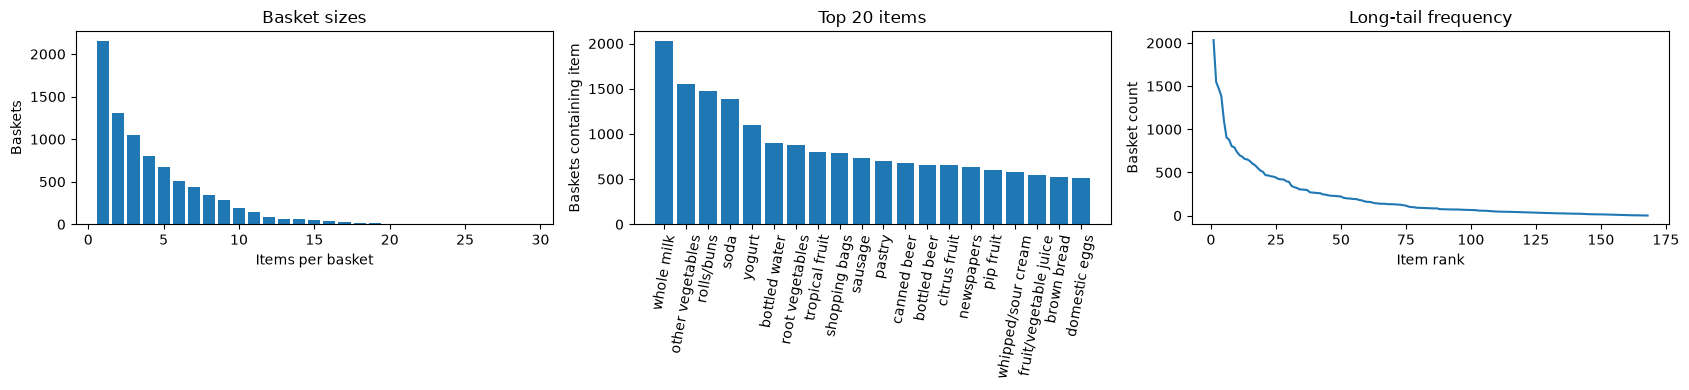

Test size is observed size after target removal, not original size. No test label/prevalence is inferred.


In [2]:
train=load_split('groceries_train.csv',EXPECTED_TRAIN); test=load_split('groceries_test.csv',EXPECTED_TEST)
if set(train.basket_id)&set(test.basket_id): raise ValueError('Train/test basket_id overlap')
if any(TARGET in b for b in test.items_list): raise ValueError('Test contains target')
train_baskets=train.items_list.tolist(); test_baskets=test.items_list.tolist()
train_vocab=sorted({x for b in train_baskets for x in b}); test_vocab={x for b in test_baskets for x in b}; all_vocab=set(train_vocab)|test_vocab
if set(ITEM_TO_GROUP)!=all_vocab: raise ValueError(f'Taxonomy coverage mismatch; missing={all_vocab-set(ITEM_TO_GROUP)}, extra={set(ITEM_TO_GROUP)-all_vocab}')
train_matrix=pd.DataFrame(item_matrix(train_baskets,train_vocab),columns=train_vocab,index=train.basket_id)
train_matrix.index.name='basket_id'; train['basket_size']=train_matrix.sum(axis=1).astype(int).to_numpy()
summary=pd.DataFrame([{'split':'train','baskets':len(train),'items':len(train_vocab),'mean_size':train.basket_size.mean(),'median':train.basket_size.median(),'min':train.basket_size.min(),'q25':train.basket_size.quantile(.25),'q75':train.basket_size.quantile(.75),'max':train.basket_size.max()},
 {'split':'test_visible_after_target_removal','baskets':len(test),'items':len(test_vocab),'mean_size':test.basket_size.mean(),'median':test.basket_size.median(),'min':test.basket_size.min(),'q25':test.basket_size.quantile(.25),'q75':test.basket_size.quantile(.75),'max':test.basket_size.max()}])
display(summary.round(3)); print('Boolean matrix',train_matrix.shape,'row sums match:',np.array_equal(train_matrix.sum(axis=1),train.basket_size))
print('Train/test/union vocab:',len(train_vocab),len(test_vocab),len(all_vocab),'| test-only:',sorted(test_vocab-set(train_vocab)))
top_items=train_matrix.sum().sort_values(ascending=False).head(20).rename('basket_count').reset_index();top_items.columns=['item','basket_count'];top_items['support']=top_items.basket_count/len(train);display(top_items)
q1,q3=train.basket_size.quantile([.25,.75]); fence=q3+1.5*(q3-q1); content=[tuple(sorted(b)) for b in train_baskets]
near=[('cream','whipped/sour cream'),('cream cheese','soft cheese'),('curd','curd cheese'),('canned beer','bottled beer'),('liquor','liqueur'),('prosecco','sparkling wine'),('frozen fruits','berries'),('frozen vegetables',TARGET),('whole milk','UHT-milk'),('fruit/vegetable juice','misc. beverages')]
near=[p for p in near if set(p)<=all_vocab]
quality=pd.DataFrame([
 ['single-item baskets',int(train.basket_size.eq(1).sum()),len(train),'Retain; only exclude from supervised protocol as required.'],
 ['large baskets above Tukey fence',int(train.basket_size.gt(fence).sum()),len(train),f'Fence {fence:.2f}; inspect, do not auto-delete.'],
 ['duplicate contents beyond first',len(content)-len(set(content)),len(train),'Keep distinct basket IDs; not proven ingestion error.'],
 ['train/test ID overlap',len(set(train.basket_id)&set(test.basket_id)),len(test),'Must be zero.'],
 ['near-name pairs for review',len(near),len(all_vocab),'; '.join(f'{a} / {b}' for a,b in near)],
 ['labels containing uppercase',sum(any(c.isupper() for c in x) for x in all_vocab),len(all_vocab),'Preserve exact source labels; review casing.']],columns=['check','count','n','decision/evidence'])
quality['rate_percent']=100*quality['count']/quality.n;display(quality)
y_all=train_matrix[TARGET].astype(int).to_numpy(); eligible_mask=train.basket_size.ge(2).to_numpy()
prevalence=pd.DataFrame([{'population':'all train','n':len(train),'positive':int(y_all.sum()),'prevalence':y_all.mean()},
 {'population':'original basket size >=2','n':int(eligible_mask.sum()),'positive':int(y_all[eligible_mask].sum()),'prevalence':y_all[eligible_mask].mean()}]);display(prevalence.assign(percent=100*prevalence.prevalence).round(4))
mapping=pd.DataFrame([{'item':x,'group':ITEM_TO_GROUP[x],'group_name':GROUP_NAMES[ITEM_TO_GROUP[x]]} for x in sorted(ITEM_TO_GROUP)])
print('Taxonomy:',mapping['item'].nunique(),'items,',mapping.group.nunique(),'groups');display(mapping.groupby(['group','group_name']).size().rename('item_count').reset_index())
(OUTPUT_DIR/'data'/'mappings').mkdir(exist_ok=True,parents=True); mapping.to_csv(OUTPUT_DIR/'data'/'mappings'/'item_to_group.csv',index=False)
alternatives=pd.DataFrame([{'item':item,'primary_group':ITEM_TO_GROUP[item],'alternative_group':alternate,'reason':reason} for item,(_primary,alternate,reason) in AMBIGUOUS_ITEMS.items() if item in ITEM_TO_GROUP])
display(alternatives)
alternatives.to_csv(OUTPUT_DIR/'data'/'mappings'/'item_group_alternatives.csv',index=False)
fig,ax=plt.subplots(1,3,figsize=(17,4)); counts=train.basket_size.value_counts().sort_index();ax[0].bar(counts.index,counts.values);ax[0].set(xlabel='Items per basket',ylabel='Baskets',title='Basket sizes')
ax[1].bar(top_items['item'],top_items.basket_count);ax[1].tick_params(axis='x',rotation=80);ax[1].set(title='Top 20 items',ylabel='Baskets containing item')
allcounts=train_matrix.sum().sort_values(ascending=False);ax[2].plot(np.arange(1,len(allcounts)+1),allcounts.values);ax[2].set(xlabel='Item rank',ylabel='Basket count',title='Long-tail frequency');plt.tight_layout();plt.show()
print('Test size is observed size after target removal, not original size. No test label/prevalence is inferred.')

## 2. Mẫu thường xuyên và luật kết hợp
**Phụ trách khác – chưa làm trong phần Thắng.**

In [3]:
# TODO: Phần 2 do thành viên phụ trách luật kết hợp triển khai.

## 3. Phân lớp
**Phụ trách khác – chưa làm trong phần Thắng.**

In [4]:
# TODO: Phần 3 do thành viên phụ trách phân lớp triển khai.

## 4. Phân cụm
**Phụ trách khác – chưa làm trong phần Thắng.**

In [5]:
# TODO: Phần 4 do thành viên phụ trách phân cụm triển khai.

## 5. Phát hiện giỏ hàng bất thường
**Phụ trách khác – chưa làm trong phần Thắng.**

In [6]:
# TODO: Phần 5 do thành viên phụ trách phát hiện bất thường triển khai.

## 6. Phản biện, rủi ro và xu hướng
**Phụ trách chung/khác – chưa làm trong phần Thắng.**

In [7]:
# TODO: Hoàn thiện Phần 6 sau khi có kết quả các phần của nhóm.